# 02 — Exploratory Cardiovascular Analysis

**Input:** `data/processed/cardiovascular_data.csv` produced by notebook 01.  
**Objective:** Explore associations of blood pressure with age, BMI and cholesterol, and differences by demographic groups.  
**Output:** descriptive tables and figures in `reports/figures/`.

**Scope:** Unweighted exploratory analysis of observed participants, **not** population inference. NHANES survey weights, clustering and stratification will be incorporated into notebook 03 for nationally representative estimates and valid uncertainty intervals. The analyses here are observational and noncausal.

## 1. Load the prepared dataset

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BASE = Path.cwd().resolve()
if BASE.name.lower() == 'notebooks': BASE = BASE.parent
DATA_FILE = BASE / 'data' / 'processed' / 'cardiovascular_data.csv'
FIG = BASE / 'reports' / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
if not DATA_FILE.exists():
    raise FileNotFoundError('Run notebook 01 first to create data/processed/cardiovascular_data.csv')
data = pd.read_csv(DATA_FILE)
assert data.SEQN.is_unique
print(f'Loaded {len(data):,} adult participants')
display(data.head())

Loaded 5,569 adult participants


,SEQN,RIDAGEYR,sex,age_group,sbp_mean,dbp_mean,sbp_n_readings,dbp_n_readings,sbp_excluded_readings,dbp_excluded_readings,high_measured_bp,bmi,total_cholesterol_mg_dl,hdl_mg_dl,told_hypertension,bp_medication,mec_weight,SDMVSTRA,SDMVPSU
0,93705.0,66.0,Female,60–79,200.000000,68.000000,2,2,0,0,1.0,31.7,157.0,60.0,Yes,Yes,8338.419786,145.0,2.0
1,93708.0,66.0,Female,60–79,142.000000,76.000000,3,3,0,0,1.0,23.7,209.0,88.0,Yes,Yes,14372.488765,138.0,2.0
2,93709.0,75.0,Female,60–79,118.666667,66.666667,3,3,0,0,0.0,38.9,176.0,65.0,Yes,Yes,12277.556662,136.0,1.0
3,93711.0,56.0,Male,40–59,101.333333,66.666667,3,3,0,0,0.0,21.3,238.0,72.0,No,NaN,12390.919724,134.0,2.0
4,93713.0,67.0,Male,60–79,104.666667,72.000000,3,3,0,0,0.0,23.5,184.0,48.0,No,NaN,166841.660681,140.0,1.0


## 2. Clinical variables: descriptive overview (unweighted)

In [2]:
variables = ['RIDAGEYR','sbp_mean','dbp_mean','bmi','total_cholesterol_mg_dl','hdl_mg_dl']
summary = data[variables].describe().round(2)
display(summary)
print('Valid systolic BP measurements:', data.sbp_mean.notna().sum())

,RIDAGEYR,sbp_mean,dbp_mean,bmi,total_cholesterol_mg_dl,hdl_mg_dl
count,5569.00,4999.00,4984.00,5175.00,4937.00,4937.00
mean,51.50,127.13,72.96,29.85,188.07,53.26
std,17.81,20.16,11.87,7.40,41.29,15.68
min,20.00,72.67,32.00,14.20,76.00,10.00
25%,36.00,112.67,65.33,24.80,160.00,42.00
50%,53.00,124.00,72.67,28.60,185.00,51.00
75%,66.00,137.33,80.00,33.60,213.00,61.00
max,80.00,238.00,135.33,86.20,446.00,189.00


Valid systolic BP measurements: 4999


## 3. Question 1 — How is age associated with systolic blood pressure?

The scatter plot uses individual participants with valid age and blood pressure. The smooth line is a visual aid only; it does not adjust for confounding or survey design.

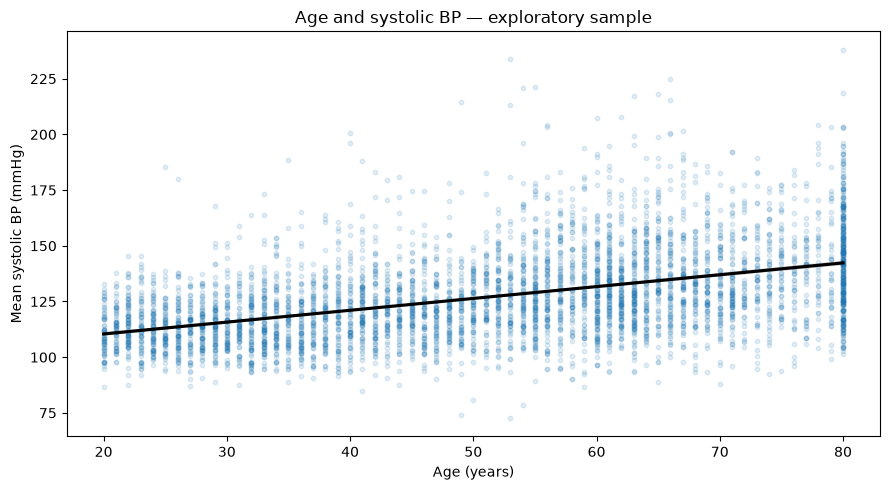

In [3]:
fig, ax = plt.subplots(figsize=(9,5))
sns.regplot(data=data, x='RIDAGEYR', y='sbp_mean',
            scatter_kws={'alpha':0.13,'s':10}, line_kws={'color':'black'}, ax=ax)
ax.set(xlabel='Age (years)', ylabel='Mean systolic BP (mmHg)', title='Age and systolic BP — exploratory sample')
fig.tight_layout()
fig.savefig(FIG/'age_vs_sbp.png', dpi=160)
plt.show()

## 4. Question 2 — Does measured systolic BP vary across age groups and sex?

Boxplots show the distribution of readings across survey participants, not population-level prevalence estimates.

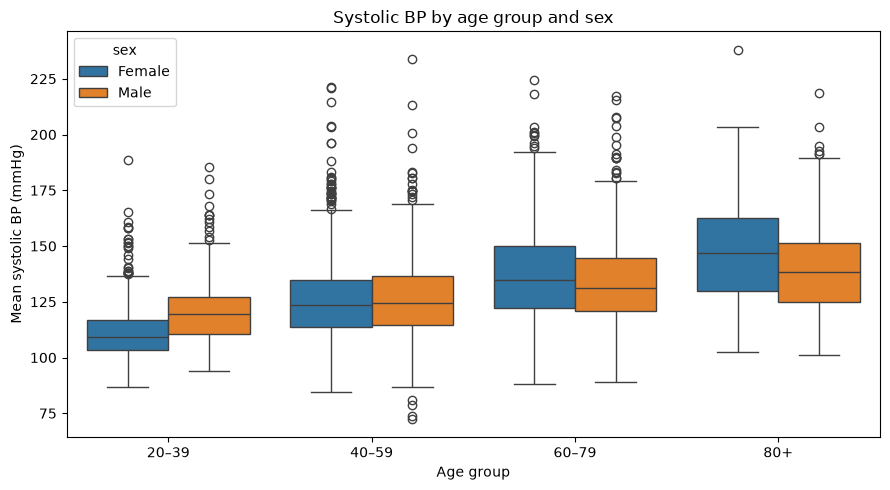

n  mean_sbp  median_sbp
age_group sex                              
20–39     Female  792     111.3       109.3
          Male    704     120.1       119.3
40–59     Female  836     126.2       123.7
          Male    744     126.6       124.7
60–79     Female  767     137.0       134.7
          Male    806     133.6       131.2
80+       Female  176     146.9       146.7
          Male    174     140.7       138.3

In [4]:
fig, ax = plt.subplots(figsize=(9,5))
sns.boxplot(data=data, x='age_group', y='sbp_mean', hue='sex',
            order=['20–39','40–59','60–79','80+'], ax=ax)
ax.set(xlabel='Age group', ylabel='Mean systolic BP (mmHg)', title='Systolic BP by age group and sex')
fig.tight_layout()
fig.savefig(FIG/'sbp_by_age_and_sex.png',dpi=160)
plt.show()
display(data.groupby(['age_group','sex'],observed=True).agg(
    n=('sbp_mean','count'),mean_sbp=('sbp_mean','mean'),median_sbp=('sbp_mean','median')).round(1))

## 5. Question 3 — How is BMI related to measured systolic blood pressure?

The unadjusted trend is exploratory; the next statistical notebook will examine adjustment for age and sex.

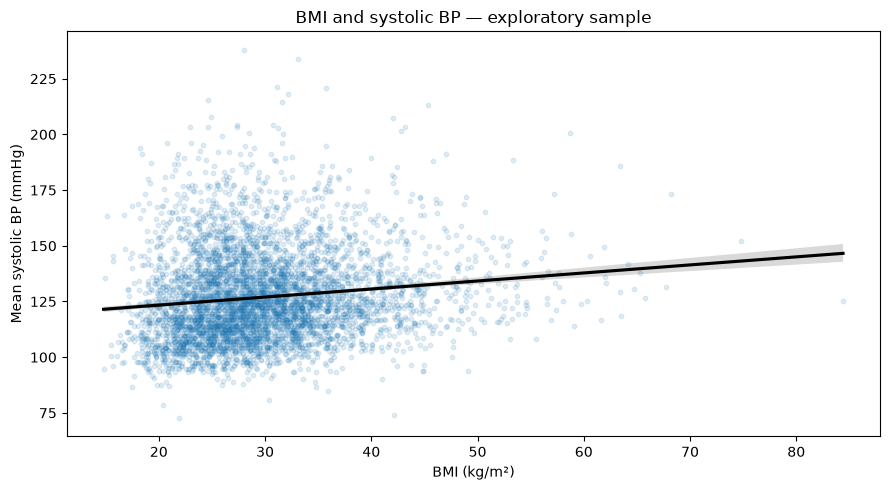

In [5]:
fig, ax = plt.subplots(figsize=(9,5))
sns.regplot(data=data, x='bmi', y='sbp_mean',
            scatter_kws={'alpha':0.13,'s':10}, line_kws={'color':'black'}, ax=ax)
ax.set(xlabel='BMI (kg/m²)', ylabel='Mean systolic BP (mmHg)', title='BMI and systolic BP — exploratory sample')
fig.tight_layout()
fig.savefig(FIG/'bmi_vs_sbp.png',dpi=160)
plt.show()

## 6. Correlation exploration

Pearson correlations are calculated using available observations pairwise and are **not survey-weighted**. Correlation neither establishes causation nor automatically implies clinical importance.

,RIDAGEYR,sbp_mean,dbp_mean,bmi,total_cholesterol_mg_dl,hdl_mg_dl
RIDAGEYR,1.00,0.47,-0.03,-0.01,0.05,0.07
sbp_mean,0.47,1.00,0.44,0.13,0.10,0.02
dbp_mean,-0.03,0.44,1.00,0.10,0.14,-0.05
bmi,-0.01,0.13,0.10,1.00,-0.01,-0.27
total_cholesterol_mg_dl,0.05,0.10,0.14,-0.01,1.00,0.19
hdl_mg_dl,0.07,0.02,-0.05,-0.27,0.19,1.00


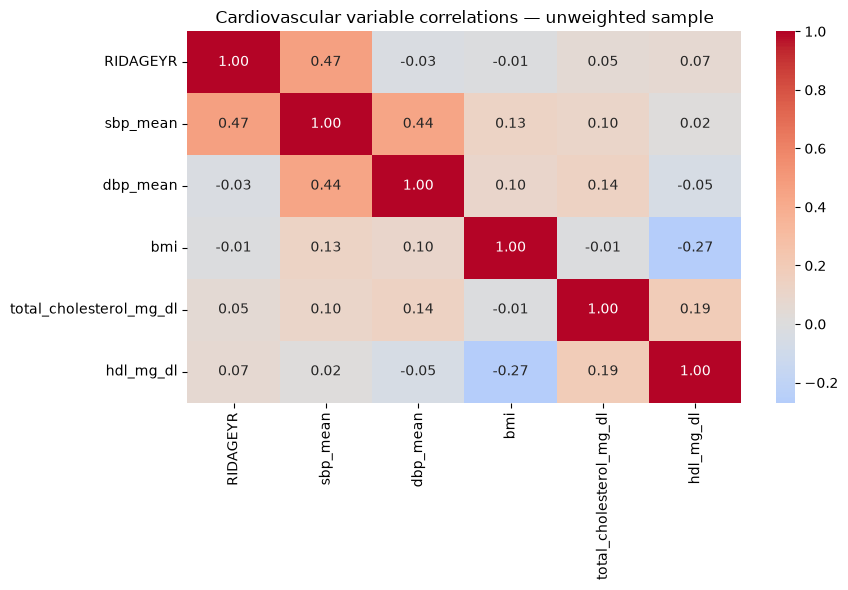

In [6]:
corr = data[variables].corr()
display(corr.round(2))
fig, ax = plt.subplots(figsize=(9,6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Cardiovascular variable correlations — unweighted sample')
fig.tight_layout()
fig.savefig(FIG/'correlation_matrix.png',dpi=160)
plt.show()

## 7. Medication-status descriptive check

`bp_medication` has significant missingness due in part to NHANES questionnaire skip patterns. The following summary covers **only respondents with an explicit Yes/No response** and must not be interpreted as treatment effectiveness. We avoid causal comparison because treated and untreated participants differ in clinical indication and other confounders.

In [7]:
med = data.loc[data.bp_medication.isin(['Yes','No'])].copy()
print('Respondents with explicit yes/no medication status:',len(med))
display(med.groupby('bp_medication').agg(
    participants=('SEQN','size'),
    sbp_available=('sbp_mean','count'),
    mean_sbp=('sbp_mean','mean'),
    mean_age=('RIDAGEYR','mean'),
    mean_bmi=('bmi','mean')).round(2))

Respondents with explicit yes/no medication status: 1937


,participants,sbp_available,mean_sbp,mean_age,mean_bmi
bp_medication,,,,,
No,289,254,139.64,52.81,32.06
Yes,1648,1496,136.97,64.30,31.57


## What comes next?

**Notebook 03:** use NHANES survey design (MEC weights, stratification, PSU) for estimates and interval uncertainty, and interpret adjusted relationships appropriately. We will not infer causal effects from this cross-sectional sample.

**Portfolio tip:** Screenshots and summary findings go in the README only after interpreting actual results. Outputs under `reports/figures/` can be tracked in Git if you choose.